# Correct the coherence for finite-look bias

NISAR coherence is estimated from a finite number of looks, which biases it high where the true coherence is low (Bamler and Hartl, 1998). This shows how the number of looks is found over open water, where the true coherence is ~0, and how the expected-coherence equation is inverted to get the true coherence for the 80 m and 20 m grids. The method follows Hoppinen et al. (2026), Sec. 3.6.

In [1]:
from shapely.geometry import box
import geopandas as gpd
import numpy as np
import xarray as xr
import rioxarray  # noqa: F401
from rasterio.enums import Resampling
import matplotlib.pyplot as plt
from seaborn import set_theme
set_theme()

import sys
import os
from pathlib import Path

# import from this repo 
project_root = str(Path(os.getcwd()).parent)
if project_root not in sys.path:
    sys.path.append(project_root)

%load_ext autoreload
%autoreload 2
from scripts.download import download_nisar, build_cube
from scripts.coherence import expected_coherence, debias_coherence, effective_looks_factor

/bsuhome/julialober/miniforge3/envs/coherence_v2/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


First, we setup logging to get useful information and error messages. 

In [2]:
import logging

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True 
)

## Download NISAR data over water

The true coherence over a lake or reservoir is assumed to be zero, so any coherence there is bias. Fill in the track, frame, dates and bounding box of a water body; use the same track and frame as the study area so the multilooking matches.

In [3]:
track = 19   # TODO
frame = 21   # TODO
start = '2025-12-01'   # TODO e.g. '2025-12-01'
end = '2026-04-30'     # TODO e.g. '2026-04-30'
proc_code = 'P05023'   # TODO e.g. 'P05023'

# TODO: bounding box of the water body, in the crs below
bounds = (-106.6162836479317, 38.81212109259412, -106.5482160142688, 38.86012135462189)   # (minx, miny, maxx, maxy)
crs = 'EPSG:4326'   # TODO e.g. 'EPSG:32613'
shp = gpd.GeoDataFrame(geometry=[box(*bounds)], crs=crs)

data_dir = "../data/"
out = data_dir + f"nisar/water/track{str(track).zfill(3)}_frame{str(frame).zfill(3)}"
layers = ['unwrapped_phase', 'coherence_unwrapped',  # 80 m interferogram 
          'wrapped_phase', 'coherence_wrapped']      # 20 m interferogram 

Download the clipped coherence layers. Files that already exist are skipped.

In [4]:
(grans, files) = download_nisar(
    track=track,
    frame=frame,
    start_date=start,
    end_date=end,
    aoi=shp,
    layers=layers,
    output_dir=out,
    crid=proc_code
)

2026-10-29 12:55:43,964 - INFO - Searching ASF for NISAR GUNW granules: track=19, frame=21, 2025-12-01–2026-04-30
/bsuhome/julialober/miniforge3/envs/coherence_v2/lib/python3.11/site-packages/tzlocal/utils.py:39: UserWarning: Timezone offset does not match system offset: 0 != -21600. Please, check your config files.
  warnings.warn(msg)
2026-10-29 12:55:44,153 - INFO - SEARCH: Using search opts {
    "frame": [
        21
    ],
    "processingLevel": [
        "GUNW"
    ],
    "relativeOrbit": [
        19
    ],
    "start": "2025-12-01T00:00:00Z",
    "end": "2026-04-30T00:00:00Z",
    "dataset": [
        "NISAR"
    ]
}
2026-10-29 12:55:44,159 - INFO - SEARCH: Using cmr endpoint: "https://cmr.earthdata.nasa.gov/search/granules.umm_json"
2026-10-29 12:55:44,160 - INFO - SUBQUERY 1: Beginning subquery with opts: {
    "frame": [
        21
    ],
    "processingLevel": [
        "GUNW"
    ],
    "relativeOrbit": [
        19
    ],
    "start": "2025-12-01T00:00:00Z",
    "end": "

Build a data cube for each grid, then plot the coherence over the water.

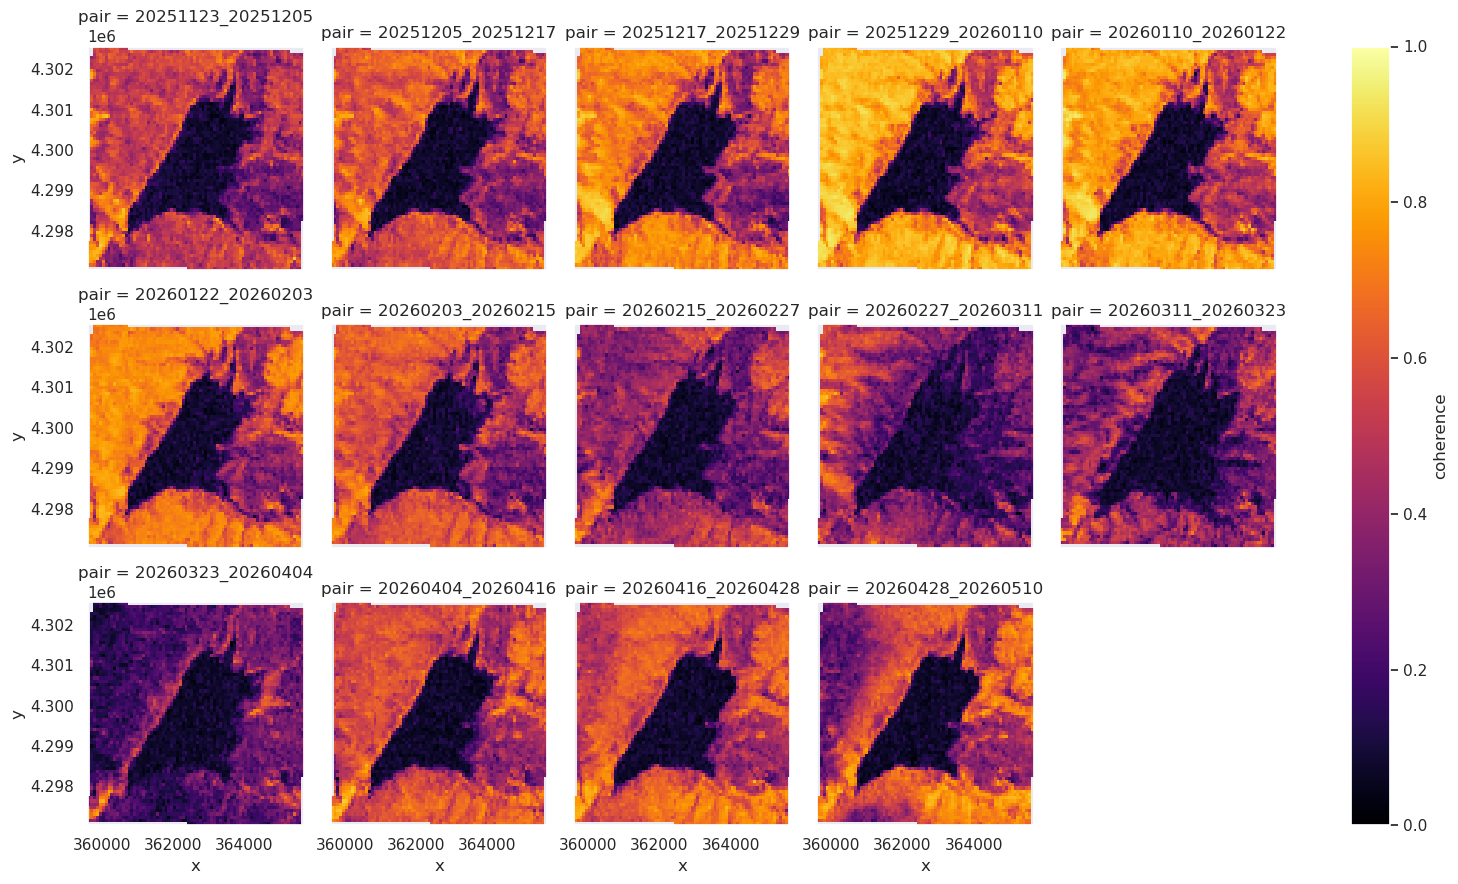

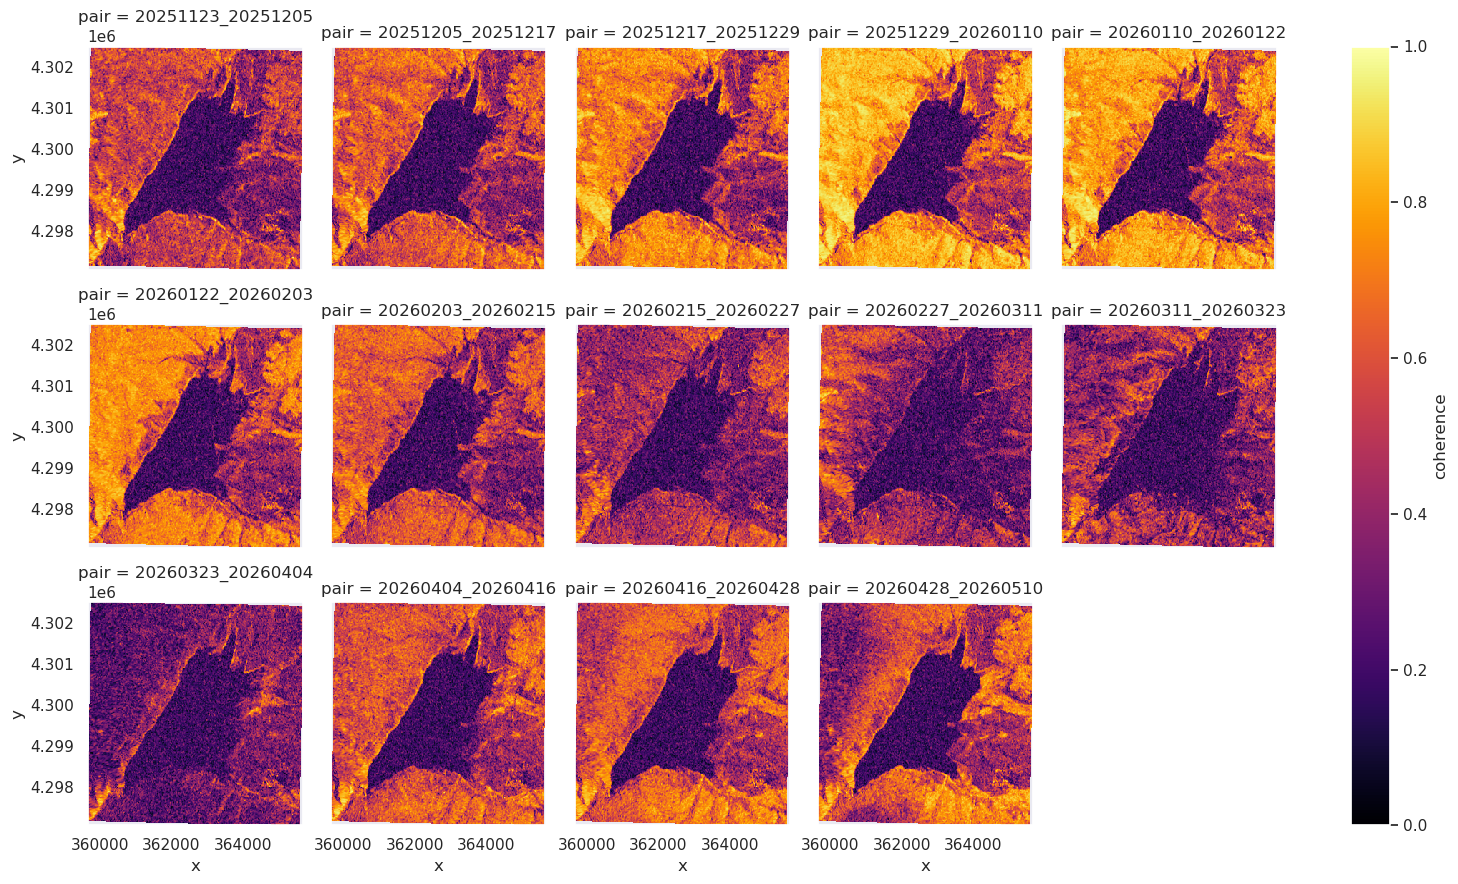

In [5]:
wrapped_files = [f for f in files if "coherence_wrapped" in str(f)]
unwrapped_files = [f for f in files if "coherence_unwrapped" in str(f)]

water_20m = build_cube(wrapped_files, "coherence", utc_offset_hours=-7)     # 20 m grid
water_80m = build_cube(unwrapped_files, "coherence", utc_offset_hours=-7)  # 80 m grid
# water_20m = water_20m.rio.write_crs(water_20m.attrs['crs'])
# water_80m = water_80m.rio.write_crs(water_80m.attrs['crs'])

water_80m['coherence'].plot(col='pair', col_wrap=5, cmap='inferno', vmin=0, vmax=1)
water_20m['coherence'].plot(col='pair', col_wrap=5, cmap='inferno', vmin=0, vmax=1)

## True looks

NISAR multilooks the interferogram 5x6 for the 20 m layer and 13x16 for the 80 m layer, so the nominal looks are N = 30 and 208. Geocoding resamples these pixels, so neighbors are partly correlated and the effective looks are L = N / f, where f is an oversampling factor.

In [6]:
n_20 = 5 * 6
n_80 = 13 * 16

Over water the true coherence is zero at both resolutions, so f is the value for which the debiased 20 m and 80 m coherences agree. Water pixels are those with 80 m coherence below 0.2, which removes coherent shoreline pixels, and the 20 m coherence is block-averaged onto the 80 m grid so both are sampled on the same footprint.

In [7]:
coh_80 = water_80m['coherence'].sel(pair='20251229_20260110')
coh_20 = water_20m['coherence'].sel(pair='20251229_20260110').rio.reproject_match(water_80m, resampling=Resampling.average)

is_water = coh_20 < 0.22
coh_80_water = coh_80.where(is_water).mean().item()
coh_20_water = coh_20.where(is_water).mean().item()
print(f"mean water coherence: 20 m = {coh_20_water:.3f}, 80 m = {coh_80_water:.3f}")

mean water coherence: 20 m = 0.186, 80 m = 0.083


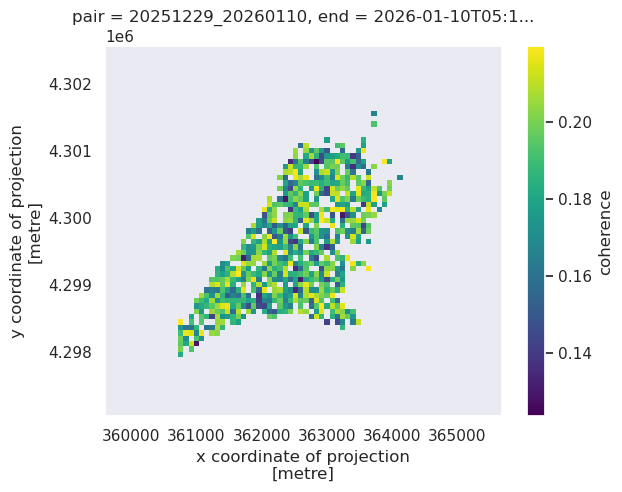

In [8]:
coh_20.where(is_water).plot()

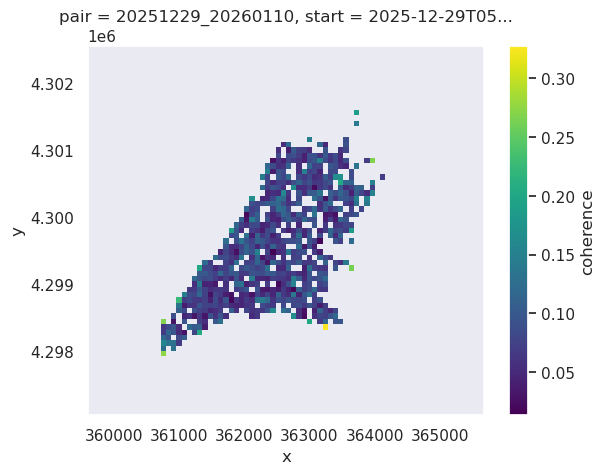

In [9]:
coh_80.where(is_water).plot()

In [10]:
f = effective_looks_factor(coh_20_water, coh_80_water, n_20, n_80)
L_20 = n_20 / f
L_80 = n_80 / f
print(f"f = {f:.2f}, L_20 = {L_20:.0f}, L_80 = {L_80:.0f}")

f = 1.23, L_20 = 24, L_80 = 169


## Invert the Bamler equation

Eq. (62) of Bamler and Hartl (1998) gives the expected sample coherence for a true coherence and number of looks. It overestimates low coherence and approaches the 1:1 line as the looks increase. Inverting it, which `debias_coherence` does by interpolation, gives the true coherence from the observed coherence.

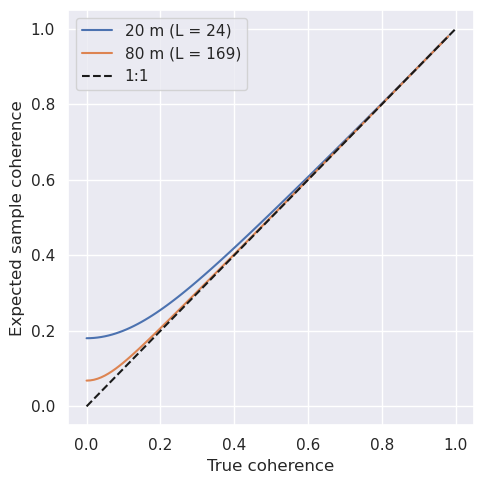

In [11]:
true = np.linspace(0, 0.98, 100)

fig, ax = plt.subplots(figsize=(5, 5))
for L, label in [(L_20, '20 m'), (L_80, '80 m')]:
    ax.plot(true, expected_coherence(true, L), label=f'{label} (L = {L:.0f})')
ax.plot([0, 1], [0, 1], 'k--', label='1:1')
ax.set_xlabel('True coherence')
ax.set_ylabel('Expected sample coherence')
ax.legend()
plt.tight_layout()

Check the inversion by passing the expected coherence back through it, which should return the true coherence.

In [12]:
check = debias_coherence(xr.DataArray(expected_coherence(true, L_80)), L_80)
print(f"max round-trip error: {np.abs(check.values - true).max():.1e}")

max round-trip error: 1.0e-05


## True coherence for the NISAR cubes

Open the data cubes that were saved by the download notebook and debias the coherence of each grid with its own effective looks. The 20 m layer is debiased natively here; Hoppinen et al. (2026) block-average it to 80 m first, which leaves less residual bias.

In [14]:
zarr_dir = data_dir + f'nisar/zarrs/all_pairs/track{str(track).zfill(3)}/'
nisar_20m = xr.open_zarr(zarr_dir + 'gunw_20m.zarr')
nisar_80m = xr.open_zarr(zarr_dir + 'gunw_80m.zarr')

In [15]:
nisar_20m['coherence_true'] = debias_coherence(nisar_20m['coherence'], L_20)
nisar_80m['coherence_true'] = debias_coherence(nisar_80m['coherence'], L_80)

Plot the observed and true coherence of the first date pair to see the change.

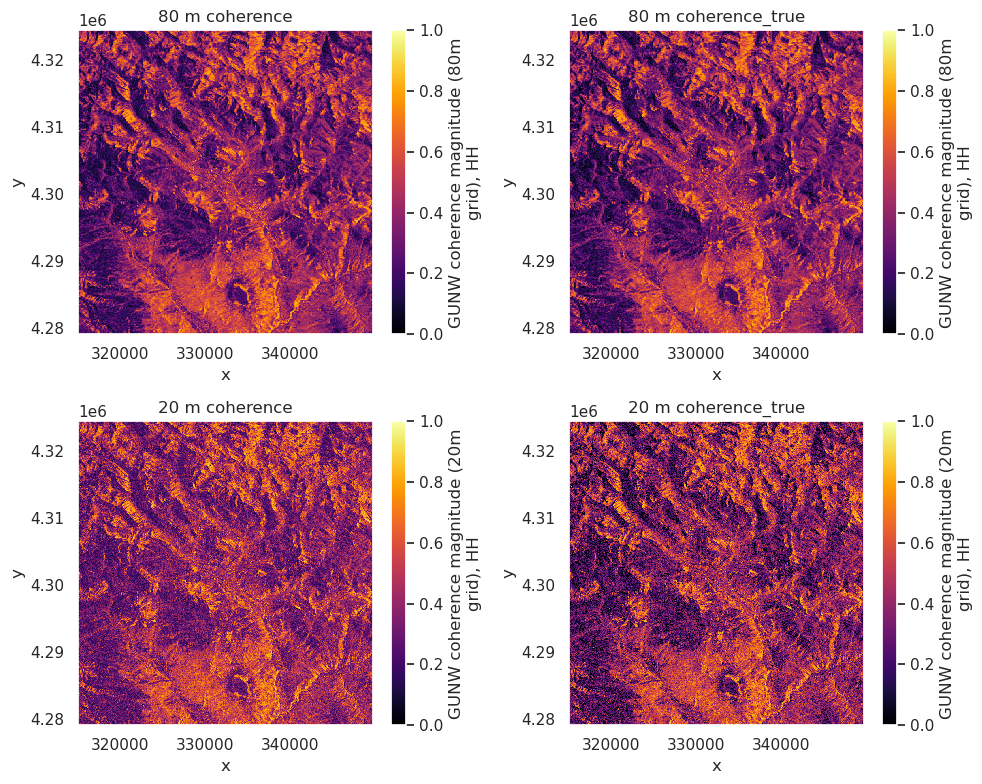

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for row, (ds, res) in enumerate([(nisar_80m, '80 m'), (nisar_20m, '20 m')]):
    for ax, var in zip(axes[row], ['coherence', 'coherence_true']):
        ds[var].isel(pair=0).squeeze().plot(ax=ax, cmap='inferno', vmin=0, vmax=1)
        ax.set_title(f'{res} {var}')
plt.tight_layout()

In [71]:
diff = nisar_80m['coherence_true'] - nisar_20m['coherence_true'].rio.reproject_match(nisar_80m, resampling=Resampling.bilinear)

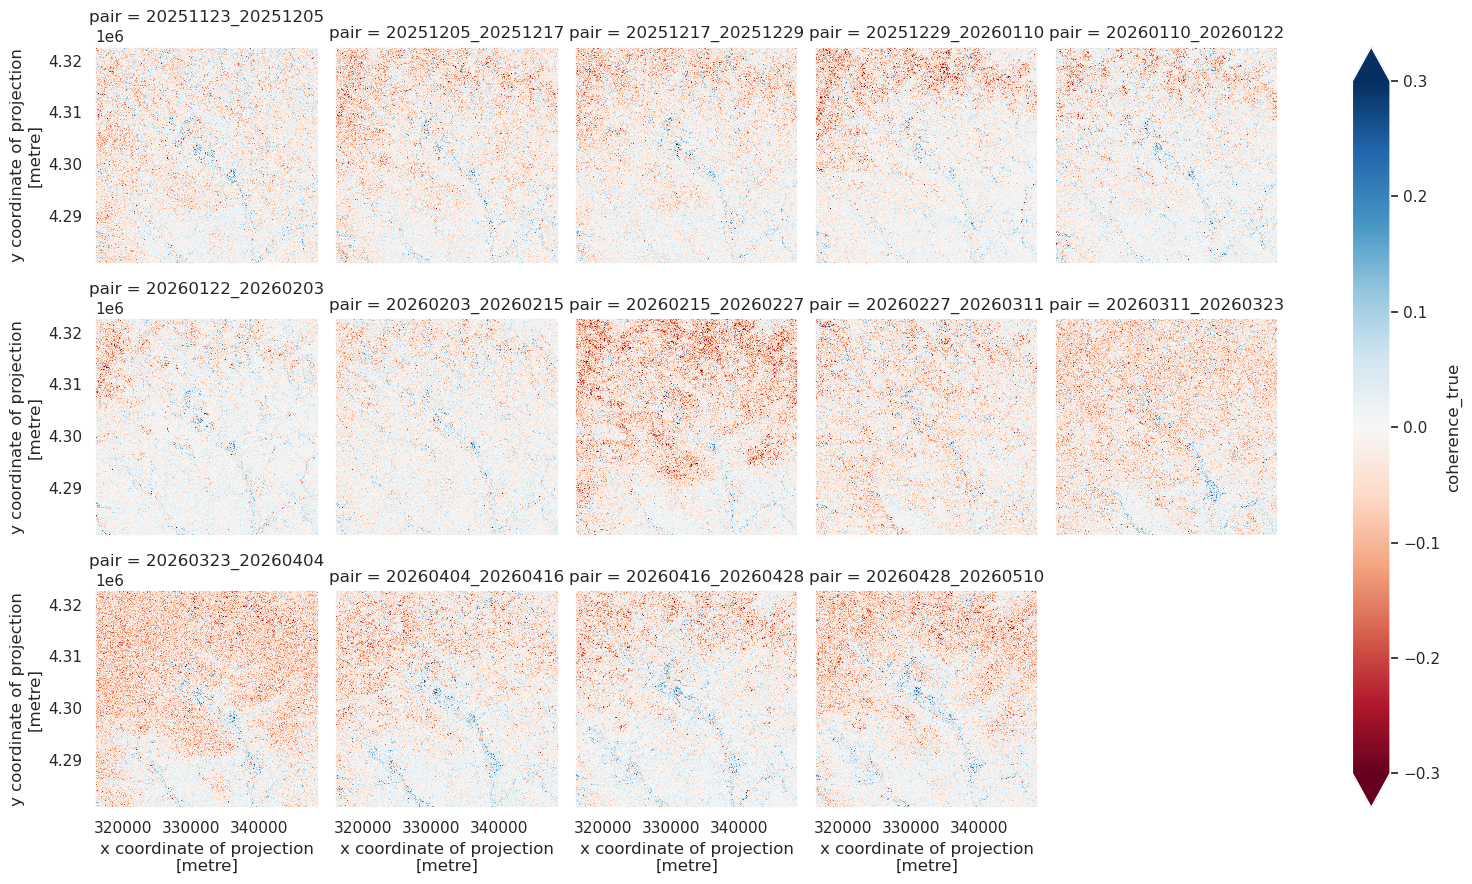

In [72]:
diff.plot(col='pair', col_wrap=5, cmap='RdBu', vmin=-0.3, vmax=0.3)

Save the true coherence back to the zarrs as a new variable, leaving the observed coherence unchanged.

In [17]:
nisar_20m[['coherence_true']].to_zarr(zarr_dir + 'gunw_20m.zarr', mode="a")
nisar_80m[['coherence_true']].to_zarr(zarr_dir + 'gunw_80m.zarr', mode="a")

/bsuhome/julialober/miniforge3/envs/coherence_v2/lib/python3.11/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/bsuhome/julialober/miniforge3/envs/coherence_v2/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=17, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/bsuhome/julialober/miniforge3/